<a href="https://colab.research.google.com/github/RealHotnCold/MLA0204-192511036/blob/main/5_Implementation_of_K_Nearest_Neighbours_(K_NN).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Implementation of K-Nearest Neighbours (K-NN) in Python

In this notebook, we will implement the K-Nearest Neighbours classification algorithm using the popular machine learning library, `scikit-learn`.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

#### 1. Generate Synthetic Data and Preprocess
We generate a 2-class classification dataset so that we can easily visualize the decision boundaries in a 2D space.

In [ ]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Generate synthetic 2D data
X, y = make_classification(n_samples=200, n_features=2, n_redundant=0, n_informative=2,
                           random_state=42, n_clusters_per_class=1)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardize features (important for distance-based algorithms like K-NN)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#### 2. Train the K-NN Classifier
We initialize the `KNeighborsClassifier` with $K=5$ and fit it to our scaled training data.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize K-NN with K=5
k = 5
knn = KNeighborsClassifier(n_neighbors=k)

# Fit the model
knn.fit(X_train, y_train)

# Predict test instances
y_pred = knn.predict(X_test)

#### 3. Evaluate the Model
Let's evaluate how well our model performed on the test data using accuracy, a confusion matrix, and a classification report.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 86.67%

Confusion Matrix:
[[28  6]
 [ 2 24]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.88        34
           1       0.80      0.92      0.86        26

    accuracy                           0.87        60
   macro avg       0.87      0.87      0.87        60
weighted avg       0.88      0.87      0.87        60



#### 4. Visualize the Decision Boundary

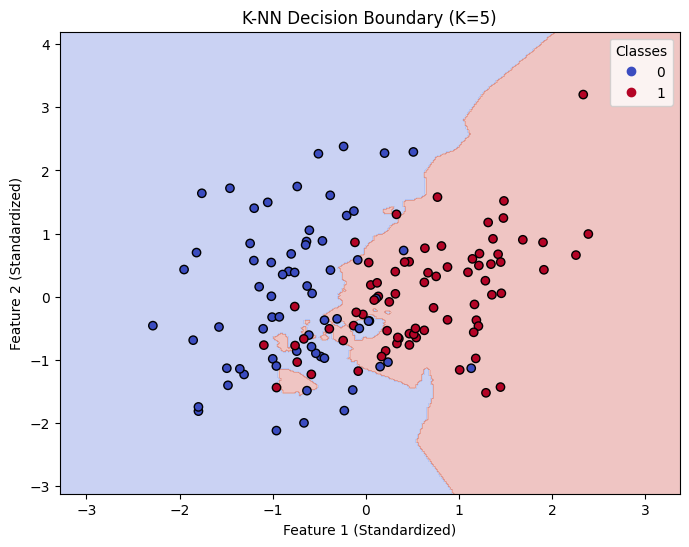

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Create mesh grid for plotting
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# Predict class for each point in the mesh grid
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundary and training points
fig = plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
scatter = plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolor='k')
plt.title(f"K-NN Decision Boundary (K={k})")
plt.xlabel("Feature 1 (Standardized)")
plt.ylabel("Feature 2 (Standardized)")
plt.legend(*scatter.legend_elements(), title="Classes")
plt.show()